# Análisis multitemporal y relación con el clima de la superficie hídrica de la Laguna de Aculeo
**Proyecto de Data Science – Magíster** · Juan Pablo Maureira · Cuerpo de agua candidato (Paine, Región Metropolitana)

Este notebook aplica a Aculeo la misma metodología del notebook de Laguna Torca (serie Landsat + CR2MET + validación cruzada temporal), pero **adaptada a una laguna que se secó casi por completo y volvió a llenarse**. Según la prensa, Aculeo estuvo unos cinco años prácticamente sin agua y recuperó superficie con las lluvias de 2023-2024 ([El Mostrador, 3-mar-2024](https://www.elmostrador.cl/cultura/2024/03/03/registros-muestran-recuperacion-de-laguna-de-aculeo-tras-cinco-anos-de-sequia/)). Eso cambia tres decisiones respecto de Torca:

| Tema | Torca | Aculeo (este notebook) |
|---|---|---|
| Escenas con área baja o caídas bruscas | Se anulan (se asumía nube) | **No se anulan por ser bajas**: la caída puede ser real. Solo se descartan escenas con poco polígono visible y valles/picos *aislados* |
| Cambio de sensor | Se resta la media de cada época (`epoca`) | Restar la media de cada época **borraría la sequía real** (2013+ es casi todo seco). Se **calibra con pares de escenas casi simultáneas** de misiones distintas (L5↔L7, L7↔L8, L9↔L8) |
| Memoria del clima | Precipitación hasta 12 meses | Se agregan acumulados de **24 y 36 meses**, porque una laguna alimentada por esteros y napa responde a varios años de lluvia |

| Sección | Contenido |
|---|---|
| 0 | Configuración e imports |
| 1 | Descarga de la serie Landsat con Google Earth Engine |
| 2 | Curación de la serie y calibración entre sensores |
| 3 | Clima: CR2MET en el píxel de Aculeo y proyecciones CR2 |
| 4 | Base mensual (sin imputación) |
| 5 | Variación anual, tendencia, quiebre y estacionalidad |
| 6 | Correlación con el clima (con tamaño de muestra efectivo) |
| 7 | Modelos con validación cruzada temporal |
| 8 | Proyección 2025-2095 (RCP 2.6 vs RCP 8.5) |
| 9 | Exportación, resumen y comparación con Torca |

## 0. Configuración e imports

In [1]:
import io
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import kendalltau, kruskal, spearmanr, theilslopes
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

try:
    from xgboost import XGBRegressor
except ImportError:
    XGBRegressor = None

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (14, 5)

In [2]:
# ----------------------------- Parámetros -----------------------------
SEMILLA = 42
GEE_PROYECTO = "master-chess-412203"
NOMBRE, SUF = "aculeo", "_aculeo"                     # sufijo para no pisar los archivos de Torca

FECHA_INICIO, FECHA_FIN = "1984-01-01", "2024-12-31"   # ventana de descarga Landsat
NUBOSIDAD_MAX = 40                                     # % CLOUD_COVER por escena (laxo): el filtro fino es la fracción de polígono válida
FRAC_VALIDA_MIN = 0.90                                 # mínimo de píxeles sin nube/sombra/relleno dentro del polígono
EXCLUIR_L7_SLC_OFF = False                             # True = descartar todo Landsat 7 posterior a la falla del SLC (como en Torca)
FALLA_SLC_L7 = "2003-05-31"

# Escenas aisladas atípicas (nube/sombra residual). Umbrales altos: la laguna SÍ cambia de verdad, pero no de un día para otro y de vuelta.
UMBRAL_REL_ATIPICO = 0.35                              # |cambio| > 35 % respecto de AMBOS vecinos...
UMBRAL_ABS_ATIPICO_HA = 20.0                           # ...y > 20 ha en términos absolutos
DIAS_VECINOS = 45                                      # vecinos a ≤ 45 días a cada lado
FECHAS_AUDITADAS = []                                  # fechas revisadas a mano en GEE ("AAAA-MM-DD")

# Calibración entre sensores con pares de escenas casi simultáneas
MAX_DIAS_PAR = 8                                       # misiones distintas pasan por la misma escena con 8 días de diferencia
MIN_PARES = 8                                          # pares mínimos para estimar un factor
AREA_MIN_PARES_HA = 20.0                               # no calibrar con áreas muy chicas (cocientes inestables)
QUIEBRE_SENSOR = "2012-06-01"                          # solo se usa si la calibración falla (variable `epoca`) y para las submuestras

FORZAR_DESCARGA = False
COL_AREA = "area_hectareas"

# ----------------------------- Rutas -----------------------------
def resolver_base():
    """Colab: carpeta del proyecto en Drive. Local: busca una carpeta 'data' junto al notebook."""
    if "google.colab" in sys.modules:
        from google.colab import drive
        drive.mount("/content/drive")
        return Path("/content/drive/MyDrive/Predicción laguna torca/data")
    for candidata in (Path("data"), Path("../data"), Path("../../data")):
        if candidata.exists():
            return candidata
    return Path("data")


BASE = resolver_base()
DIR_RAW, DIR_PROC = BASE / "raw", BASE / "processed"
DIR_RAW_LAGUNA = DIR_RAW / NOMBRE                      # opcional: archivos específicos de Aculeo (p. ej. proyecciones CR2)
DIR_PROC.mkdir(parents=True, exist_ok=True)


def buscar_archivo(patron, carpetas=(DIR_PROC, DIR_RAW)):
    """Primer archivo que coincide con el patrón (tolera diferencias de espacios/guiones en los nombres)."""
    for carpeta in carpetas:
        hallados = sorted(carpeta.glob(patron))
        if hallados:
            return hallados[0]
    return None


print("Carpeta de datos:", BASE.resolve())

Carpeta de datos: C:\Users\jp200\Escritorio\Predicción laguna torca\data


## 1. Google Earth Engine: serie de área de agua

Misma lógica que en Torca (NDWI > 0, píxeles de 30 m, cuatro misiones Landsat C02 L2), con dos diferencias:

- La máscara de calidad quita también los píxeles de **relleno** (bit 0, incluye las bandas del SLC-off de Landsat 7) y la **nube dilatada** (bit 1), además de nube (bit 3) y sombra (bit 4).
- Para cada escena se guarda `frac_valida`: la fracción del polígono que quedó con píxeles utilizables. Una escena con el 60 % del polígono tapado no mide la laguna, y eso se detecta aquí en vez de inferirlo desde el área.

El polígono es el que dibujaste (≈ 2 200 ha, bastante mayor que el espejo de agua máximo, para que quepa toda la laguna). Con la laguna seca, el área no baja a cero: queda un residuo de píxeles con NDWI > 0 (humedad del suelo, canales, cultivos regados). Se reporta como *piso de detección* en la sección 2.

Si ya existe `serie_laguna_aculeo_bruta.csv` en `data/processed`, **no se usa GEE**.

In [3]:
COORDENADAS_ACULEO = [
    [-70.8791883, -33.8513252], [-70.8947524, -33.8346246], [-70.9195943, -33.8238243],
    [-70.9312027, -33.8217027], [-70.9425789, -33.8247887], [-70.9490795, -33.842531],
    [-70.9458292, -33.8498583], [-70.9226125, -33.8633543], [-70.8959003, -33.8696664],
    [-70.8859301, -33.8639326], [-70.8791883, -33.8513252],
]
CACHE_SERIE = "serie_laguna_aculeo_bruta.csv"

# colección -> (banda verde, banda NIR)
MISIONES = {
    "LANDSAT/LT05/C02/T1_L2": ("SR_B2", "SR_B4"),
    "LANDSAT/LE07/C02/T1_L2": ("SR_B2", "SR_B4"),
    "LANDSAT/LC08/C02/T1_L2": ("SR_B3", "SR_B5"),
    "LANDSAT/LC09/C02/T1_L2": ("SR_B3", "SR_B5"),
}


def centroide_y_area(anillo):
    """Centroide (lon, lat) y área (ha) de un polígono pequeño, con proyección local aproximada."""
    lon = np.array([p[0] for p in anillo]); lat = np.array([p[1] for p in anillo])
    kx, ky = 111.32 * np.cos(np.radians(lat.mean())), 110.57          # km por grado
    x, y = (lon - lon.mean()) * kx, (lat - lat.mean()) * ky
    cruz = x[:-1] * y[1:] - x[1:] * y[:-1]
    A = cruz.sum() / 2
    cx, cy = ((x[:-1] + x[1:]) * cruz).sum() / (6 * A), ((y[:-1] + y[1:]) * cruz).sum() / (6 * A)
    return lon.mean() + cx / kx, lat.mean() + cy / ky, abs(A) * 100


LON_LAGUNA, LAT_LAGUNA, AREA_POLIGONO_HA = centroide_y_area(COORDENADAS_ACULEO)
print(f"Centroide del polígono: lon={LON_LAGUNA:.4f}, lat={LAT_LAGUNA:.4f} | área del polígono ≈ {AREA_POLIGONO_HA:.0f} ha")


def iniciar_gee():
    import ee
    try:
        ee.Initialize(project=GEE_PROYECTO)
    except Exception:
        # modo 'notebook': muestra un enlace y una casilla para pegar el código
        ee.Authenticate(auth_mode="notebook")
        ee.Initialize(project=GEE_PROYECTO)
    return ee


def descargar_serie_landsat():
    """NDWI > 0 por escena dentro del polígono. Devuelve fecha, satélite, área (ha) y fracción válida del polígono."""
    ee = iniciar_gee()
    geom = ee.Geometry.Polygon(COORDENADAS_ACULEO)

    def enmascarar(img):
        qa = img.select("QA_PIXEL")   # bit 0 relleno, bit 1 nube dilatada, bit 3 nube, bit 4 sombra de nube
        return img.updateMask(qa.bitwiseAnd(0b11011).eq(0))

    def coleccion(id_coleccion, verde, nir):
        return (ee.ImageCollection(id_coleccion).filterBounds(geom).filterDate(FECHA_INICIO, FECHA_FIN)
                .filter(ee.Filter.lt("CLOUD_COVER", NUBOSIDAD_MAX)).map(enmascarar)
                .map(lambda img: img.addBands(img.normalizedDifference([verde, nir]).rename("NDWI"))))

    def extraer(img):
        ndwi = img.select("NDWI")
        pix = ee.Image.pixelArea()
        agua = ndwi.gt(0).multiply(pix).rename("area_m2")                  # solo píxeles no enmascarados
        valida = pix.updateMask(ndwi.mask()).rename("valida_m2")           # área del polígono realmente observada
        r = agua.addBands(valida).reduceRegion(reducer=ee.Reducer.sum(), geometry=geom, scale=30, maxPixels=1e9)
        return ee.Feature(None, {"fecha": img.date().format("YYYY-MM-dd"), "area_m2": r.get("area_m2"),
                                 "valida_m2": r.get("valida_m2"), "satelite": img.get("SPACECRAFT_ID")})

    cols = [coleccion(i, *b) for i, b in MISIONES.items()]
    todas = cols[0]
    for c in cols[1:]:
        todas = todas.merge(c)
    feats = todas.map(extraer).getInfo()["features"]
    df = pd.DataFrame([f["properties"] for f in feats]).dropna(subset=["valida_m2"])
    df["area_m2"] = df["area_m2"].fillna(0)
    df["fecha"] = pd.to_datetime(df["fecha"])
    df[COL_AREA] = df["area_m2"] / 10_000
    df["frac_valida"] = (df["valida_m2"] / df["valida_m2"].quantile(0.98)).clip(upper=1)   # 1 = polígono completo
    return df[["fecha", "satelite", COL_AREA, "frac_valida"]].sort_values("fecha").reset_index(drop=True)


def cargar_serie_bruta():
    ruta = buscar_archivo(CACHE_SERIE)
    if ruta is not None and not FORZAR_DESCARGA:
        df = pd.read_csv(ruta, parse_dates=["fecha"])
        print(f"Serie cargada desde caché: {ruta.name}")
    else:
        print("Descargando desde Google Earth Engine (puede tardar varios minutos)...")
        df = descargar_serie_landsat()
        df.to_csv(DIR_PROC / CACHE_SERIE, index=False)
    # dos filas con la misma fecha y misión (escenas contiguas): se conserva la que ve más polígono
    df = (df.sort_values(["fecha", "satelite", "frac_valida"], ascending=[True, True, False])
            .drop_duplicates(subset=["fecha", "satelite"]).sort_values("fecha").reset_index(drop=True))
    print(f"{len(df)} observaciones | {df['fecha'].min().date()} → {df['fecha'].max().date()}")
    return df


df_sat = cargar_serie_bruta()
print(df_sat["satelite"].value_counts().to_string())
display(df_sat.head())

Centroide del polígono: lon=-70.9152, lat=-33.8457 | área del polígono ≈ 2201 ha
Descargando desde Google Earth Engine (puede tardar varios minutos)...
933 observaciones | 1984-12-24 → 2024-12-30
satelite
LANDSAT_7    403
LANDSAT_5    269
LANDSAT_8    205
LANDSAT_9     56


,fecha,satelite,area_hectareas,frac_valida
0,1984-12-24,LANDSAT_5,0.000000,0.0
1,1985-01-25,LANDSAT_5,1171.288582,1.0
2,1986-01-28,LANDSAT_5,1126.197396,1.0
3,1986-02-13,LANDSAT_5,1006.494752,1.0
4,1986-03-01,LANDSAT_5,959.422108,1.0


## 2. Curación de la serie y calibración entre sensores

**Curación.** Se descartan solo escenas con evidencia de problema, no escenas con área baja:

1. `frac_valida` < 90 %: nube, sombra o bandas vacías cubren demasiado polígono.
2. (Opcional, `EXCLUIR_L7_SLC_OFF`) Landsat 7 posterior a la falla del SLC. Por defecto **no** se excluye: si las bandas vacías caen fuera del polígono la escena sirve, y `frac_valida` ya filtra las que no.
3. **Valles o picos aislados:** una escena que difiere más de 35 % y 20 ha de *ambos* vecinos (a ≤ 45 días) se anula. La sequía real es una tendencia de años; una caída de un día que se recupera en el siguiente pase casi siempre es nube o sombra.
4. Fechas auditadas a mano (lista vacía por ahora).

**Calibración entre sensores.** Landsat 5, 7, 8 y 9 pasan por la misma escena con 8 días de diferencia, así que existen *pares casi simultáneos* de misiones distintas. Para cada par de misiones se calcula el cociente de áreas (área en la misión de referencia / área en la otra) y se estima su mediana con un intervalo bootstrap. Todo se lleva a la escala de **Landsat 8**. Un factor solo se aplica si el intervalo de confianza **excluye 1**; si no, se deja en 1.

Esto separa sensor de hidrología sin suponer que el nivel medio de cada época deba ser igual, que es justo lo que no puede suponerse en una laguna que se secó.

**Límite esperable:** Landsat 9 existe desde fines de 2021, cuando Aculeo estaba casi seca; con áreas menores a 20 ha los cocientes son inestables, así que es probable que L9↔L8 no tenga pares suficientes y L9 quede con factor 1 (la tabla lo dice). Si hay pocos pares L7↔L8, el notebook vuelve al esquema de Torca con la variable `epoca` y lo avisa.

,registros anulados
1. frac_valida < 90%,217
2. Landsat 7 SLC-off (no aplicado),0
3a. Valles aislados,16
3b. Picos aislados,13
4. Fechas auditadas,0


Observaciones válidas: 687 de 933


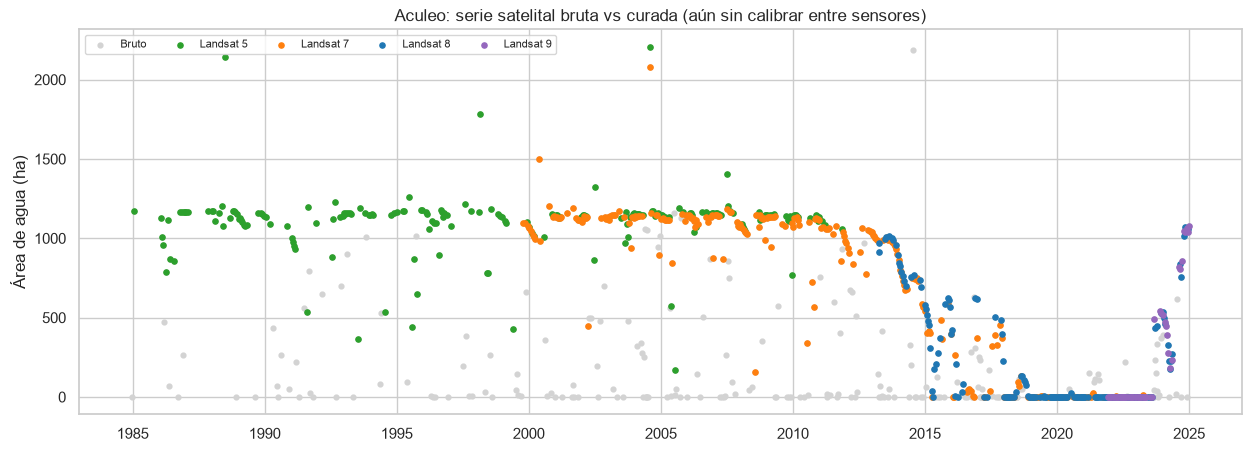

In [4]:
def curar_serie(df, fechas_auditadas=()):
    """Devuelve (serie indexada por fecha con el área anulada donde corresponde, resumen de registros anulados)."""
    s = df.set_index("fecha").sort_index().copy()
    resumen = {}

    def anular(mascara, nombre):
        antes = s[COL_AREA].notna().sum()
        s.loc[np.asarray(mascara), COL_AREA] = np.nan
        resumen[nombre] = int(antes - s[COL_AREA].notna().sum())

    anular(s["frac_valida"] < FRAC_VALIDA_MIN, f"1. frac_valida < {FRAC_VALIDA_MIN:.0%}")
    if EXCLUIR_L7_SLC_OFF:
        anular(s["satelite"].str.contains("LANDSAT_7", case=False, na=False) & (s.index > FALLA_SLC_L7), "2. Landsat 7 SLC-off")
    else:
        resumen["2. Landsat 7 SLC-off (no aplicado)"] = 0

    v = s[s[COL_AREA].notna()]
    f = v.index.values.astype("datetime64[D]").astype(int)
    d_prev, d_next = np.r_[np.inf, np.diff(f)], np.r_[np.diff(f), np.inf]
    a = v[COL_AREA].to_numpy()
    prev, nxt = np.r_[np.nan, a[:-1]], np.r_[a[1:], np.nan]
    cerca = (d_prev <= DIAS_VECINOS) & (d_next <= DIAS_VECINOS)
    u = UMBRAL_REL_ATIPICO
    valle = cerca & (a < prev * (1 - u)) & (a < nxt * (1 - u)) & ((prev - a) > UMBRAL_ABS_ATIPICO_HA) & ((nxt - a) > UMBRAL_ABS_ATIPICO_HA)
    pico = cerca & (a > prev * (1 + u)) & (a > nxt * (1 + u)) & ((a - prev) > UMBRAL_ABS_ATIPICO_HA) & ((a - nxt) > UMBRAL_ABS_ATIPICO_HA)
    anular(s.index.isin(v.index[valle]), "3a. Valles aislados")
    anular(s.index.isin(v.index[pico]), "3b. Picos aislados")
    anular(s.index.isin(pd.to_datetime(list(fechas_auditadas))), "4. Fechas auditadas")
    return s, pd.Series(resumen, name="registros anulados")


serie_curada, resumen_curacion = curar_serie(df_sat, FECHAS_AUDITADAS)
display(resumen_curacion.to_frame())
print(f"Observaciones válidas: {serie_curada[COL_AREA].notna().sum()} de {len(serie_curada)}")

COLOR_SAT = {"LANDSAT_5": "tab:green", "LANDSAT_7": "tab:orange", "LANDSAT_8": "tab:blue", "LANDSAT_9": "tab:purple"}
fig, ax = plt.subplots(figsize=(15, 5))
ax.scatter(df_sat["fecha"], df_sat[COL_AREA], s=12, color="lightgray", label="Bruto")
for sat, g in serie_curada[serie_curada[COL_AREA].notna()].groupby("satelite"):
    ax.scatter(g.index, g[COL_AREA], s=14, color=COLOR_SAT.get(sat, "k"), label=sat.replace("LANDSAT_", "Landsat "))
ax.set(title="Aculeo: serie satelital bruta vs curada (aún sin calibrar entre sensores)", ylabel="Área de agua (ha)")
ax.legend(ncol=5, fontsize=8)
plt.show()

,n_pares,factor,ic95_inf,ic95_sup,dif_mediana_ha,factor_aplicado,decision
par,,,,,,,
5 → 7,83,0.987,0.985,0.988,-15.060,0.987,se aplica
7 → 8,30,1.040,1.029,1.066,30.061,1.040,se aplica
9 → 8,16,0.989,0.954,1.032,-4.725,1.000,IC95 incluye 1: diferencia no distinguible de ...


Calibración aplicada. Factores hacia la escala de Landsat 8: {'L8': 1.0, 'L9': 1.0, 'L7': 1.04, 'L5': 1.027}


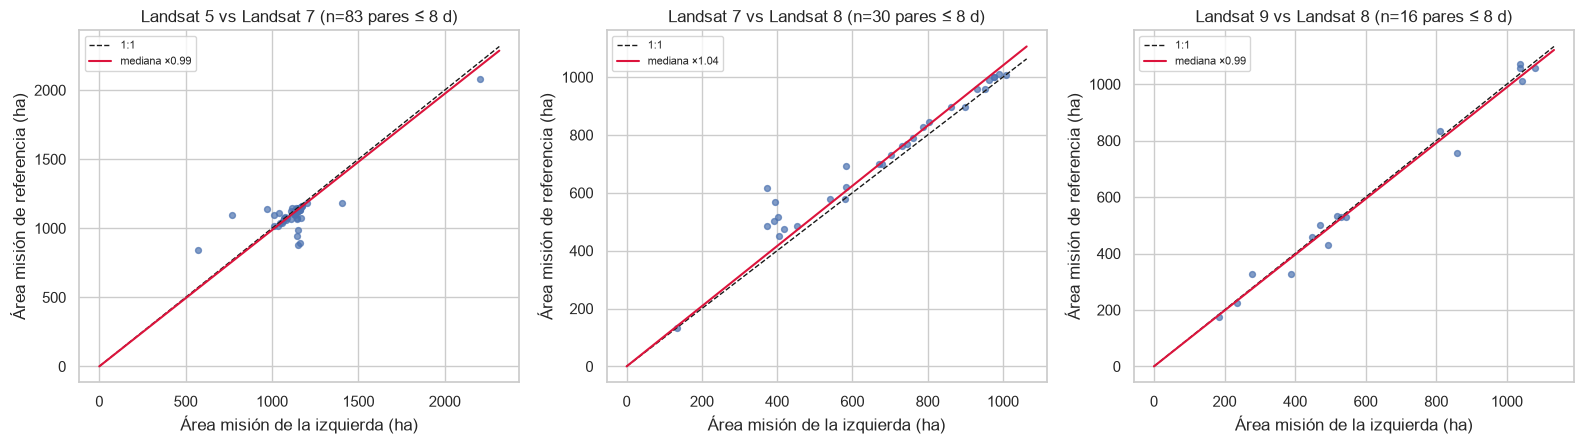

,count,mean,std,min,max
satelite,,,,,
LANDSAT_5,205,1137.4,199.2,177.4,2264.7
LANDSAT_7,271,757.2,505.4,0.0,2160.7
LANDSAT_8,160,229.3,332.0,0.0,1072.6
LANDSAT_9,51,232.3,365.7,0.0,1079.7


Piso de detección: la mediana de los 12 meses más bajos es 0.0 ha (≈ 0.0% del polígono): es el residuo con NDWI > 0 cuando la laguna está seca, no agua libre.
Fechas de esos meses: 2016-04, 2017-03, 2017-04, 2017-05, 2018-02, 2018-03, 2018-04, 2019-01, 2019-02, 2019-03, 2019-04, 2020-03


In [5]:
# ---- Calibración entre sensores con pares casi simultáneos
def pares(s, sat_x, sat_ref):
    """Para cada escena de sat_x, la escena de sat_ref más cercana en el tiempo (≤ MAX_DIAS_PAR días)."""
    v = s[s[COL_AREA].notna()]
    X, R = v.loc[v["satelite"] == sat_x, COL_AREA], v.loc[v["satelite"] == sat_ref, COL_AREA]
    filas = []
    if len(X) and len(R):
        for fx, ax_ in X.items():
            d = np.asarray((R.index - fx).days)
            j = int(np.argmin(np.abs(d)))
            if abs(d[j]) <= MAX_DIAS_PAR:
                filas.append((fx, R.index[j], ax_, R.iloc[j]))
    p = pd.DataFrame(filas, columns=["fecha_x", "fecha_ref", "area_x", "area_ref"])
    return p[(p["area_x"] >= AREA_MIN_PARES_HA) & (p["area_ref"] >= AREA_MIN_PARES_HA)].reset_index(drop=True)


def estimar_factor(sat_x, sat_ref):
    p = pares(serie_curada, sat_x, sat_ref)
    n = len(p)
    out = {"par": f"{sat_x[-1]} → {sat_ref[-1]}", "n_pares": n, "factor": np.nan, "ic95_inf": np.nan, "ic95_sup": np.nan,
           "dif_mediana_ha": np.nan, "pares": p}
    if n >= MIN_PARES:
        r = (p["area_ref"] / p["area_x"]).to_numpy()
        boot = np.median(np.random.default_rng(SEMILLA).choice(r, size=(2000, n), replace=True), axis=1)
        out.update(factor=float(np.median(r)), ic95_inf=float(np.percentile(boot, 2.5)), ic95_sup=float(np.percentile(boot, 97.5)),
                   dif_mediana_ha=float(np.median(p["area_ref"] - p["area_x"])))
    return out


def factor_a_aplicar(e):
    if np.isnan(e["factor"]):
        return 1.0, f"pocos pares ({e['n_pares']} < {MIN_PARES}): no se calibra"
    if e["ic95_inf"] <= 1 <= e["ic95_sup"]:
        return 1.0, "IC95 incluye 1: diferencia no distinguible de cero"
    return e["factor"], "se aplica"


e57, e78, e98 = (estimar_factor("LANDSAT_5", "LANDSAT_7"), estimar_factor("LANDSAT_7", "LANDSAT_8"),
                 estimar_factor("LANDSAT_9", "LANDSAT_8"))
f57, m57 = factor_a_aplicar(e57)
f78, m78 = factor_a_aplicar(e78)
f98, m98 = factor_a_aplicar(e98)

tabla_cal = pd.DataFrame([{k: v for k, v in e.items() if k != "pares"} | {"factor_aplicado": f, "decision": m}
                          for e, f, m in ((e57, f57, m57), (e78, f78, m78), (e98, f98, m98))]).set_index("par")
display(tabla_cal.round(3))

# El puente entre épocas es L7 → L8. Sin él no se puede unir L5/L7 con L8/L9 y se vuelve al esquema de Torca (variable `epoca`).
PUENTE_OK = e78["n_pares"] >= MIN_PARES
USAR_EPOCA = not PUENTE_OK
if PUENTE_OK:
    FACTORES = {"LANDSAT_8": 1.0, "LANDSAT_9": f98, "LANDSAT_7": f78, "LANDSAT_5": f57 * f78}
    print("Calibración aplicada. Factores hacia la escala de Landsat 8:", {k.replace('LANDSAT_', 'L'): round(v, 3) for k, v in FACTORES.items()})
else:
    FACTORES = {k: 1.0 for k in COLOR_SAT}
    print("No hay pares L7↔L8 suficientes: NO se calibra. Se usará la variable `epoca` como en Torca; en ese caso el salto de sensor "
          "queda confundido con el cambio real de la laguna y los resultados deben leerse con ese límite.")
if PUENTE_OK and np.isnan(e57["factor"]):
    print("Aviso: sin pares L5↔L7 suficientes; Landsat 5 se trata como Landsat 7 (sin factor propio).")

serie_curada["area_sin_calibrar_ha"] = serie_curada[COL_AREA]
serie_curada[COL_AREA] = serie_curada["area_sin_calibrar_ha"] * serie_curada["satelite"].map(FACTORES).fillna(1.0)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (e, titulo) in zip(axes, ((e57, "Landsat 5 vs Landsat 7"), (e78, "Landsat 7 vs Landsat 8"), (e98, "Landsat 9 vs Landsat 8"))):
    p = e["pares"]
    if len(p):
        ax.scatter(p["area_x"], p["area_ref"], s=18, alpha=0.7)
        lim = [0, max(p[["area_x", "area_ref"]].max()) * 1.05]
        ax.plot(lim, lim, "k--", lw=1, label="1:1")
        if not np.isnan(e["factor"]):
            ax.plot(lim, [e["factor"] * x for x in lim], color="crimson", label=f"mediana ×{e['factor']:.2f}")
        ax.legend(fontsize=8)
    ax.set(title=f"{titulo} (n={e['n_pares']} pares ≤ {MAX_DIAS_PAR} d)", xlabel="Área misión de la izquierda (ha)", ylabel="Área misión de referencia (ha)")
plt.tight_layout()
plt.show()

# ---- Resumen por sensor (con la tendencia real de por medio, las medias por sensor NO son comparables entre sí)
valido = serie_curada[serie_curada[COL_AREA].notna()]
display(valido.groupby("satelite")[COL_AREA].agg(["count", "mean", "std", "min", "max"]).round(1))

serie_mensual = serie_curada[COL_AREA].resample("MS").mean()     # meses sin dato válido quedan en NaN (no se imputan)
seco = serie_mensual.dropna().nsmallest(12)
print(f"Piso de detección: la mediana de los 12 meses más bajos es {seco.median():.1f} ha "
      f"(≈ {seco.median() / AREA_POLIGONO_HA:.1%} del polígono): es el residuo con NDWI > 0 cuando la laguna está seca, no agua libre.")
print("Fechas de esos meses:", ", ".join(d.strftime("%Y-%m") for d in sorted(seco.index)))

## 3. Clima: CR2MET en el píxel de Aculeo y proyecciones CR2

Se extrae **CR2MET v2.0** (0.05°, mensual 1979-2019) en el píxel más cercano al centroide del polígono. Si no existe `clima_cr2met_laguna_aculeo_mensual_1979_2019.csv` en `data/processed`, se genera a partir de los `.nc` de `data/raw` (los mismos de Torca).

**Límite importante:** CR2MET termina en **2019** y el momento más interesante de Aculeo es después (sequía profunda 2019-2022 y recuperación 2023-2024). Los análisis con clima cubren hasta 2019; las escenas 2020-2024 solo sirven para describir el área. Extender el clima hasta 2024 (por ejemplo con ERA5-Land para la zona de Aculeo) permitiría usar justo ese periodo.

**Proyecciones CR2:** los CSV de `data/raw` se descargaron para Torca. Si el explorador del CR2 permite elegir la ubicación, descárgalos para Aculeo y ponlos en `data/raw/aculeo/` (el notebook los usa primero). Con el método delta lo que importa es el cambio relativo de cada GCM, así que los de Torca son una aproximación razonable, pero no son los de Aculeo.

In [6]:
NC_CR2MET = {"precip": "CR2MET_pr_v2.0_mon_1979_2019_005deg.nc",
             "tmax": "CR2MET_tmax_v2.0_mon_1979_2019_005deg.nc",
             "tmin": "CR2MET_tmin_v2.0_mon_1979_2019_005deg.nc"}
VAR_NC = {"precip": "pr", "tmax": "tmax", "tmin": "tmin"}
CSV_CLIMA = f"clima_cr2met_laguna_{NOMBRE}_mensual_1979_2019.csv"


def extraer_cr2met_desde_nc():
    """Serie mensual del píxel más cercano al centroide. El tiempo viene como 'months since 1978-12-15' (xarray no lo decodifica):
    se abre con decode_times=False y las fechas se construyen a mano (492 meses desde 1979-01)."""
    import xarray as xr
    fechas = pd.date_range("1979-01-01", periods=492, freq="MS")
    cols = {}
    for var, nombre in NC_CR2MET.items():
        ruta = buscar_archivo(nombre, (DIR_RAW,))
        if ruta is None:
            raise FileNotFoundError(f"Falta {nombre} en {DIR_RAW}")
        ds = xr.open_dataset(ruta, decode_times=False)
        px = ds[VAR_NC[var]].sel(lat=LAT_LAGUNA, lon=LON_LAGUNA, method="nearest")
        assert len(px) == len(fechas), "el número de meses del .nc no coincide con lo esperado"
        dist = max(abs(float(px.lat) - LAT_LAGUNA), abs(float(px.lon) - LON_LAGUNA))
        assert dist < 0.05, f"el píxel más cercano está a {dist:.3f}° del centroide: ¿el .nc cubre Aculeo?"
        cols[var] = pd.Series(px.values.astype(float), index=fechas)
        print(f"{var}: píxel lat={float(px.lat):.3f}, lon={float(px.lon):.3f}")
    df = pd.DataFrame(cols).rename_axis("fecha")
    df.rename(columns={"precip": "precip_mm", "tmax": "tmax_c", "tmin": "tmin_c"}).to_csv(DIR_PROC / CSV_CLIMA)
    return df


def cargar_cr2met():
    ruta = buscar_archivo(f"clima_cr2met_laguna_{NOMBRE}*.csv")      # patrón específico: no confundir con el CSV de Torca
    if ruta is not None:
        df = pd.read_csv(ruta, parse_dates=["fecha"]).set_index("fecha")
        df = df.rename(columns={"precip_mm": "precip", "tmax_c": "tmax", "tmin_c": "tmin"})
        print("CR2MET cargado desde", ruta.name)
        return df
    print("No hay CSV de CR2MET para Aculeo: extrayendo desde los .nc ...")
    return extraer_cr2met_desde_nc()


df_clima = cargar_cr2met()[["precip", "tmax", "tmin"]].sort_index()
FIN_CLIMA = df_clima.index.max()
print(f"CR2MET: {len(df_clima)} meses | {df_clima.index.min().date()} → {FIN_CLIMA.date()} | faltantes: {int(df_clima.isna().sum().sum())}")
print(f"Precipitación media anual 1986-2005: {df_clima.loc['1986':'2005', 'precip'].sum() / 20:.0f} mm")
display(df_clima.describe().round(2))

No hay CSV de CR2MET para Aculeo: extrayendo desde los .nc ...
precip: píxel lat=-33.825, lon=-70.925
tmax: píxel lat=-33.825, lon=-70.925
tmin: píxel lat=-33.825, lon=-70.925
CR2MET: 492 meses | 1979-01-01 → 2019-12-01 | faltantes: 0
Precipitación media anual 1986-2005: 554 mm


,precip,tmax,tmin
count,492.00,492.00,492.00
mean,43.28,22.45,6.86
std,70.74,5.48,3.77
min,0.00,12.43,-0.57
25%,0.00,17.34,3.57
50%,13.22,22.45,6.58
75%,55.75,28.04,10.50
max,509.96,31.98,13.27


In [7]:
# ---- Proyecciones CR2 (GCMs por escenario). Columnas emparejadas por NOMBRE de GCM.
SUFIJO_VAR = {"precip": "pr", "tmax": "tasmax", "tmin": "tasmin"}
PATRON_PROY = {"precip": "proyeccin-de-la-precipit*.csv",
               "tmax": "proyeccin-de-la-temperat*max*.csv",
               "tmin": "proyeccin-de-la-temperat*min*.csv"}


def cargar_proyeccion_cr2(patron):
    """CSV del CR2: separador ';', decimal ',', con BOM. Busca primero en data/raw/aculeo."""
    ruta = buscar_archivo(patron, (DIR_RAW_LAGUNA, DIR_RAW, DIR_PROC))
    if ruta is None:
        raise FileNotFoundError(f"No encuentro '{patron}' en {DIR_RAW}")
    print(f"  {patron} → {ruta.parent.name}/{ruta.name}")
    texto = ruta.read_bytes().decode("utf-8-sig", errors="ignore")
    df = pd.read_csv(io.StringIO(texto), sep=";", decimal=",", thousands=".")
    df["DateTime"] = pd.to_datetime(df["DateTime"])
    return df.set_index("DateTime")


print("Archivos de proyección usados:")
proy = {v: cargar_proyeccion_cr2(p) for v, p in PATRON_PROY.items()}
if not DIR_RAW_LAGUNA.exists():
    print("AVISO: no hay carpeta data/raw/aculeo; las proyecciones son las descargadas para Torca (ver nota de la sección 3).")

INICIO_PROY, DESDE_LAGS = "2025-01-01", "2021-12-01"      # DESDE_LAGS: 36 meses antes del inicio, para construir los acumulados
VARS_CLIMA = ("precip", "tmax", "tmin")


def gcms_completos(escenario, desde=DESDE_LAGS):
    """GCMs presentes en las tres variables, sin huecos desde `desde` y con 'historical' 1986-2005 (línea base)."""
    por_variable = []
    for var in VARS_CLIMA:
        suf, df, ok = SUFIJO_VAR[var], proy[var], set()
        for c in df.columns:
            if c.endswith(f"_{suf} {escenario}"):
                g = c[: -len(f"_{suf} {escenario}")]
                hist = f"{g}_{suf} historical"
                if df[c].loc[desde:].notna().all() and hist in df.columns and df[hist].loc["1986":"2005"].notna().all():
                    ok.add(g)
        por_variable.append(ok)
    return sorted(set.intersection(*por_variable))


for esc in ("rcp26", "rcp85"):
    print(f"{esc}: {len(gcms_completos(esc))} GCMs completos | último año disponible: {proy['precip'].index.max().year}")

Archivos de proyección usados:
  proyeccin-de-la-precipit*.csv → raw/proyeccin-de-la-precipit.csv
  proyeccin-de-la-temperat*max*.csv → raw/proyeccin-de-la-temperat max.csv
  proyeccin-de-la-temperat*min*.csv → raw/proyeccin-de-la-temperat min.csv
AVISO: no hay carpeta data/raw/aculeo; las proyecciones son las descargadas para Torca (ver nota de la sección 3).
rcp26: 26 GCMs completos | último año disponible: 2095
rcp85: 39 GCMs completos | último año disponible: 2095


## 4. Base mensual para análisis y modelos

- **Sin imputación.** Todo el análisis usa meses con área observada (ya calibrada entre sensores si hubo pares suficientes).
- **Memoria del clima.** Además de la precipitación del mes y sus rezagos de 1 y 2 meses, se usan acumulados de 3, 12, **24 y 36 meses** y las temperaturas.
- La variable `epoca` (L5/L7 vs L8/L9) solo entra si la calibración falló (`USAR_EPOCA`).

481 meses (1984-12-01 → 2024-12-01) | 343 con área observada (71%) | sin imputar
Meses con área observada por década: {1980: 29, 1990: 55, 2000: 98, 2010: 104, 2020: 57}
Meses con área observada Y clima CR2MET (con acumulados completos): 286
Variable `epoca` en los modelos: NO (el área ya está calibrada entre sensores)


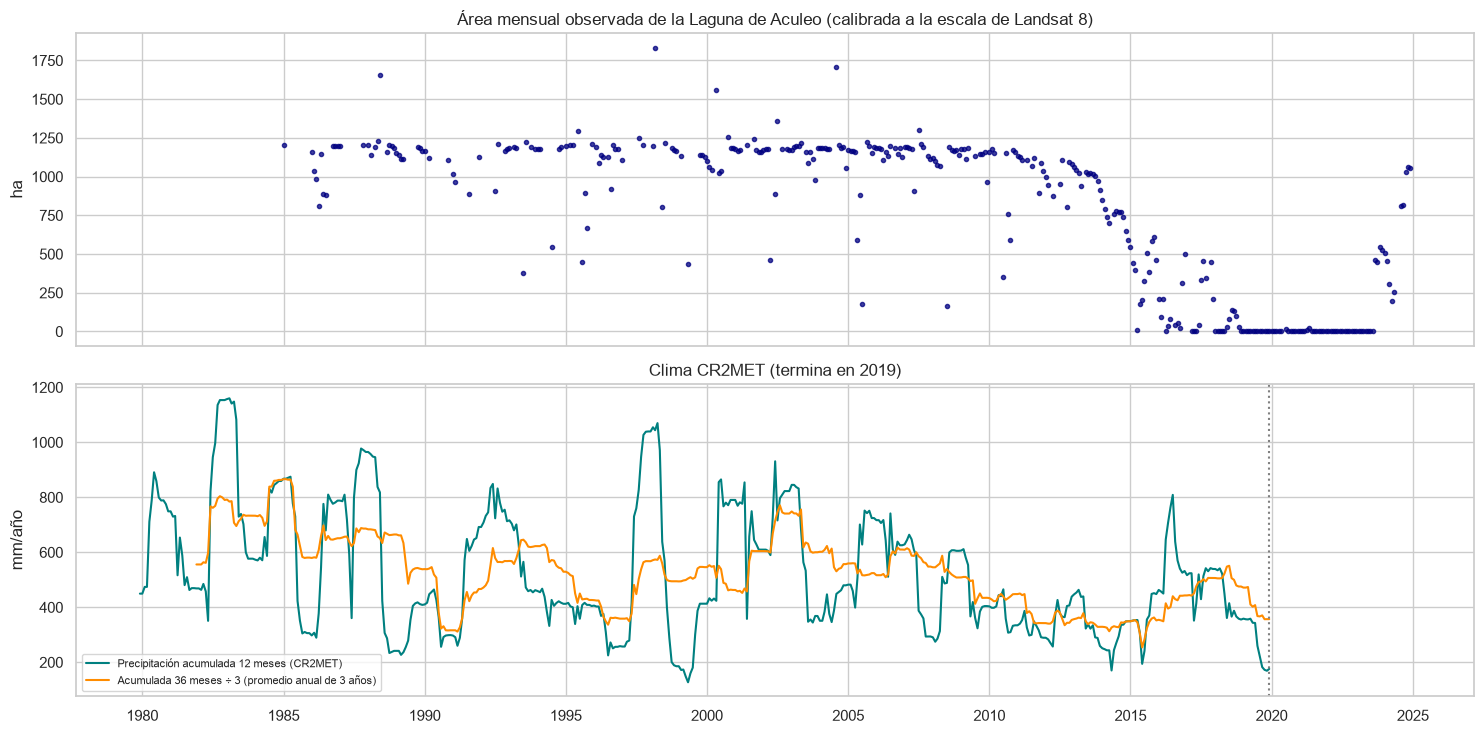

In [8]:
def construir_features(clima):
    """Precipitación, rezagos, acumulados de 3-36 meses, temperaturas y estacionalidad cíclica."""
    out = clima[["precip", "tmax", "tmin"]].copy()
    out["p1"] = out["precip"].shift(1)
    out["p2"] = out["precip"].shift(2)
    for k in (3, 12, 24, 36):
        out[f"p{k}"] = out["precip"].rolling(k).sum()
    out["mes_sin"] = np.sin(2 * np.pi * out.index.month / 12)
    out["mes_cos"] = np.cos(2 * np.pi * out.index.month / 12)
    out["epoca"] = (out.index > pd.Timestamp(QUIEBRE_SENSOR)).astype(int)
    return out


def anomalia_estacional(s):
    """Resta la media de cada mes calendario."""
    return s - s.groupby(s.index.month).transform("mean")


df_modelo = serie_mensual.to_frame(COL_AREA).join(construir_features(df_clima), how="left")
mes = df_modelo.index.month
df_modelo["mes_sin"], df_modelo["mes_cos"] = np.sin(2 * np.pi * mes / 12), np.cos(2 * np.pi * mes / 12)   # existen en TODO el periodo
df_modelo["epoca"] = (df_modelo.index > pd.Timestamp(QUIEBRE_SENSOR)).astype(int)
df_modelo["area_anom_est"] = anomalia_estacional(df_modelo[COL_AREA])

VARS_CLIMA_MODELO = ["precip", "p1", "p2", "p3", "p12", "p24", "p36", "tmax", "tmin"]
FEATS_BASE = ["mes_sin", "mes_cos"] + (["epoca"] if USAR_EPOCA else [])
FEATS_CLIMA = FEATS_BASE + VARS_CLIMA_MODELO

n_obs = df_modelo[COL_AREA].notna().sum()
print(f"{len(df_modelo)} meses ({df_modelo.index.min().date()} → {df_modelo.index.max().date()}) | "
      f"{n_obs} con área observada ({n_obs / len(df_modelo):.0%}) | sin imputar")
print("Meses con área observada por década:", df_modelo[COL_AREA].notna().groupby((df_modelo.index.year // 10) * 10).sum().to_dict())
n_con_clima = df_modelo.loc[:FIN_CLIMA].dropna(subset=[COL_AREA] + VARS_CLIMA_MODELO).shape[0]
print(f"Meses con área observada Y clima CR2MET (con acumulados completos): {n_con_clima}")
print("Variable `epoca` en los modelos:", "SÍ (la calibración entre sensores falló)" if USAR_EPOCA else "NO (el área ya está calibrada entre sensores)")

fig, axes = plt.subplots(2, 1, figsize=(15, 7.5), sharex=True)
axes[0].plot(df_modelo.index, df_modelo[COL_AREA], ".", color="navy", alpha=0.75)
axes[0].set(title="Área mensual observada de la Laguna de Aculeo (calibrada a la escala de Landsat 8)", ylabel="ha")
p12 = df_clima["precip"].rolling(12).sum()
axes[1].plot(p12.index, p12.values, color="teal", label="Precipitación acumulada 12 meses (CR2MET)")
axes[1].plot(df_clima["precip"].rolling(36).sum().div(3).index, df_clima["precip"].rolling(36).sum().div(3).values,
             color="darkorange", label="Acumulada 36 meses ÷ 3 (promedio anual de 3 años)")
axes[1].axvline(FIN_CLIMA, color="gray", ls=":")
axes[1].set(ylabel="mm/año", title="Clima CR2MET (termina en 2019)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. Variación anual, tendencia, quiebre y estacionalidad

La variación anual se calcula como **anomalía respecto de la climatología mensual** y solo para años con ≥ 3 meses observados, para que un año con pocas escenas de verano no parezca más seco solo por cuándo pasó el satélite.

Variación anual neta (años con ≥ 3 meses observados):


,area_media_obs,meses_obs,anom_ha,variacion_anom_ha,precip_anual_mm
fecha,,,,,
1986,1049.2,10,285.9,NaN,788.0
1988,1239.7,9,470.0,NaN,241.5
1989,1151.7,7,326.2,-143.8,408.7
1990,1131.6,3,272.2,-54.0,298.9
1991,999.9,4,172.6,-99.6,692.0
1992,1115.6,4,332.1,159.6,713.0
1993,1076.2,7,299.9,-32.2,462.2
1994,1055.4,5,236.2,-63.7,412.7
1995,1014.2,8,244.2,7.9,404.6


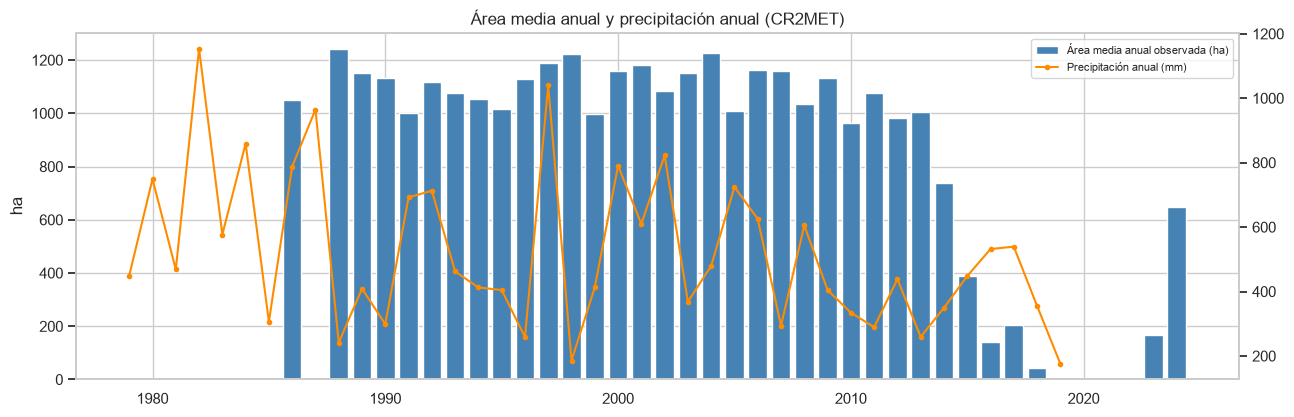

In [9]:
area = df_modelo[COL_AREA]
clim_mes = area.groupby(area.index.month).mean()
anom_clim = area - clim_mes.reindex(area.index.month).values
anual = pd.DataFrame({"area_media_obs": area.groupby(area.index.year).mean(),
                      "meses_obs": area.groupby(area.index.year).count(),
                      "anom_ha": anom_clim.groupby(anom_clim.index.year).mean()})
anual = anual[anual["meses_obs"] >= 3].copy()
anual["variacion_anom_ha"] = anual["anom_ha"].diff().where(anual.index.to_series().diff() == 1)
p_anual = df_clima["precip"].groupby(df_clima.index.year).sum()
anual["precip_anual_mm"] = p_anual.reindex(anual.index)
print("Variación anual neta (años con ≥ 3 meses observados):")
display(anual.round(1))

fig, ax = plt.subplots(figsize=(15, 4.5))
ax.bar(anual.index, anual["area_media_obs"], color="steelblue", label="Área media anual observada (ha)")
ax.set(ylabel="ha", title="Área media anual y precipitación anual (CR2MET)")
ax2 = ax.twinx()
ax2.plot(p_anual.index, p_anual.values, color="darkorange", marker="o", ms=3, label="Precipitación anual (mm)")
ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper right", fontsize=8)
plt.show()

Tendencia de la anomalía anual: n=38 años | tau=-0.48 (p=0.000) | pendiente Theil-Sen=-22.67 ha/año
Pettitt: quiebre tras 2009 (p ≈ 0.0000); anomalía media antes = +327.3 ha, después = -345.8 ha
El área está calibrada entre sensores, así que el quiebre no se explica (al menos en su mayor parte) por el cambio de misión.

Kruskal-Wallis entre los 12 meses (años con ≥ 6 meses observados, n=316): H = 25.4, p = 0.0081 → hay estacionalidad estadísticamente detectable.


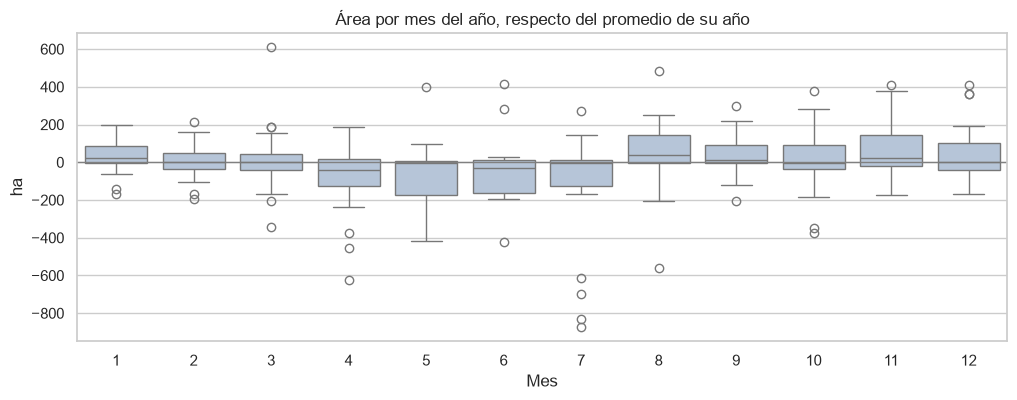

In [10]:
# ---- Tendencia (Kendall) y quiebre (Pettitt) sobre la anomalía anual
def pettitt(x):
    """Test de Pettitt: (posición del quiebre, estadístico K, p-valor aproximado)."""
    x = np.asarray(x, dtype=float)
    n = len(x)
    r = pd.Series(x).rank().values
    U = 2 * np.cumsum(r) - np.arange(1, n + 1) * (n + 1)
    K = np.abs(U).max()
    return int(np.abs(U).argmax()), K, min(1.0, 2 * np.exp(-6 * K ** 2 / (n ** 3 + n ** 2)))


tau, p_tau = kendalltau(anual.index, anual["anom_ha"].values)
pend = theilslopes(anual["anom_ha"].values, anual.index)[0]
print(f"Tendencia de la anomalía anual: n={len(anual)} años | tau={tau:+.2f} (p={p_tau:.3f}) | pendiente Theil-Sen={pend:+.2f} ha/año")
t_q, K_q, p_q = pettitt(anual["anom_ha"].values)
anio_q = int(anual.index[t_q])
print(f"Pettitt: quiebre tras {anio_q} (p ≈ {p_q:.4f}); anomalía media antes = {anual['anom_ha'].iloc[:t_q + 1].mean():+.1f} ha, "
      f"después = {anual['anom_ha'].iloc[t_q + 1:].mean():+.1f} ha")
if not USAR_EPOCA:
    print("El área está calibrada entre sensores, así que el quiebre no se explica (al menos en su mayor parte) por el cambio de misión.")
elif abs(anio_q - pd.Timestamp(QUIEBRE_SENSOR).year) <= 2:
    print("Sin calibración: el quiebre coincide con el cambio de sensor y podría ser en parte un artefacto.")

# ---- Estacionalidad: se compara cada mes con el promedio de SU año (para que la tendencia no se mezcle con el ciclo anual)
n_mes_obs = area.groupby(area.index.year).transform("count")
dentro = (area - area.groupby(area.index.year).transform("mean"))[n_mes_obs >= 6].dropna()
H, p_kw = kruskal(*[g.values for _, g in dentro.groupby(dentro.index.month)])
print(f"\nKruskal-Wallis entre los 12 meses (años con ≥ 6 meses observados, n={len(dentro)}): H = {H:.1f}, p = {p_kw:.4f} "
      f"→ {'hay' if p_kw < 0.05 else 'NO hay'} estacionalidad estadísticamente detectable.")
fig, ax = plt.subplots(figsize=(12, 4))
sns.boxplot(x=dentro.index.month, y=dentro.values, ax=ax, color="lightsteelblue")
ax.axhline(0, color="gray", lw=1)
ax.set(title="Área por mes del año, respecto del promedio de su año", xlabel="Mes", ylabel="ha")
plt.show()

## 6. Correlación con el clima

Spearman entre el área y cada variable climática, en dos versiones: **cruda** y con **anomalías estacionales** en ambas (se quita el ciclo mensual). Se agregan dos controles que en Torca resultaron decisivos:

- **`n_efectivo`**: como el área y los acumulados de lluvia cambian lento, los meses consecutivos no son independientes. El tamaño de muestra efectivo (aproximación de Bartlett con la autocorrelación de lag 1 de ambas series) dice cuántas observaciones independientes hay realmente. Un p-valor minúsculo con `n_efectivo` pequeño **no** es evidencia sólida.
- **Estabilidad en el tiempo:** la misma correlación antes y después de 2012. Si el signo o la fuerza cambian, probablemente solo refleja un episodio (una sequía) y no una relación estable.

,rho_cruda,rho_anom_estacional,p,n,n_efectivo,rho_hasta_2012,n_hasta_2012,rho_desde_2013,n_desde_2013,R2_aprox
variable,,,,,,,,,,
precip,-0.129,-0.073,0.216,286,247.069,-0.161,203,-0.071,83,0.005
p1,-0.042,0.022,0.707,286,247.062,-0.034,203,0.000,83,0.000
p2,0.013,0.020,0.732,286,247.079,-0.058,203,0.033,83,0.000
p3,-0.062,0.007,0.911,286,51.238,-0.113,203,-0.085,83,0.000
p12,0.361,0.297,0.000,286,18.963,0.245,203,-0.198,83,0.088
p24,0.445,0.395,0.000,286,14.120,0.255,203,-0.348,83,0.156
p36,0.533,0.468,0.000,286,11.924,0.199,203,-0.564,83,0.219
tmax,0.111,-0.062,0.298,286,178.123,0.056,203,-0.276,83,0.004
tmin,0.123,-0.147,0.013,286,172.359,-0.071,203,-0.316,83,0.022


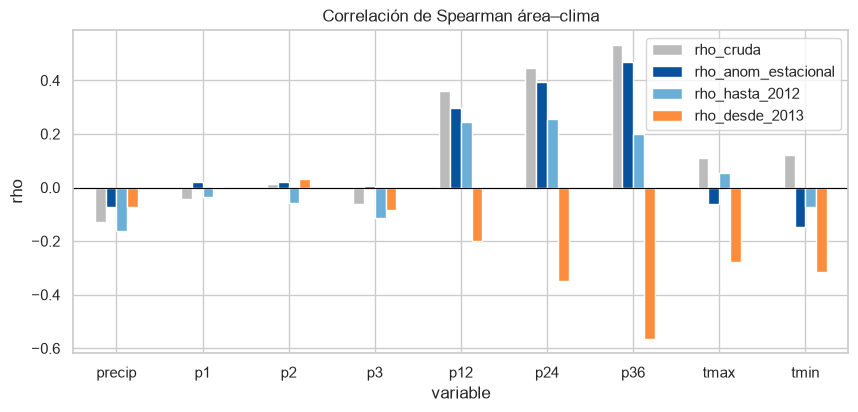

Mayor |rho| con anomalías estacionales: p36 (rho=+0.47, R² ≈ 22%, n=286, n efectivo ≈ 12).


In [11]:
VARS_CORR = VARS_CLIMA_MODELO
clima_f = construir_features(df_clima)
clima_anom = clima_f[VARS_CORR].apply(anomalia_estacional)
a_anom = df_modelo["area_anom_est"]


def rho_par(a, b):
    par = pd.concat([a, b], axis=1).dropna()
    if len(par) < 10:
        return np.nan, np.nan, len(par)
    r, p = spearmanr(par.iloc[:, 0], par.iloc[:, 1])
    return r, p, len(par)


def n_efectivo(n, x, y):
    r1, r2 = x.autocorr(1), y.autocorr(1)          # sobre la grilla mensual completa (pares consecutivos con dato)
    if pd.isna(r1) or pd.isna(r2):
        return np.nan
    rr = max(r1 * r2, 0.0)
    return n * (1 - rr) / (1 + rr)


corte = pd.Timestamp(QUIEBRE_SENSOR)
filas = []
for v in VARS_CORR:
    r_cr, _, _ = rho_par(area, clima_f[v])
    r_an, p_an, n_an = rho_par(a_anom, clima_anom[v])
    r_ant, _, n_ant = rho_par(a_anom.loc[:corte], clima_anom[v].loc[:corte])
    r_pos, _, n_pos = rho_par(a_anom.loc[corte:], clima_anom[v].loc[corte:])
    filas.append((v, r_cr, r_an, p_an, n_an, n_efectivo(n_an, a_anom, clima_anom[v]), r_ant, n_ant, r_pos, n_pos))
tabla_corr = pd.DataFrame(filas, columns=["variable", "rho_cruda", "rho_anom_estacional", "p", "n", "n_efectivo",
                                          "rho_hasta_2012", "n_hasta_2012", "rho_desde_2013", "n_desde_2013"]).set_index("variable")
tabla_corr["R2_aprox"] = tabla_corr["rho_anom_estacional"] ** 2
display(tabla_corr.round(3))

fig, ax = plt.subplots(figsize=(10, 4.2))
tabla_corr[["rho_cruda", "rho_anom_estacional", "rho_hasta_2012", "rho_desde_2013"]].plot.bar(
    ax=ax, color=["#bbbbbb", "#08519c", "#6baed6", "#fd8d3c"])
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Correlación de Spearman área–clima", ylabel="rho")
plt.xticks(rotation=0)
plt.show()

mejor = tabla_corr["rho_anom_estacional"].abs().idxmax()
RHO_MAX = float(tabla_corr.loc[mejor, "rho_anom_estacional"])
print(f"Mayor |rho| con anomalías estacionales: {mejor} (rho={RHO_MAX:+.2f}, R² ≈ {RHO_MAX ** 2:.0%}, n={int(tabla_corr.loc[mejor, 'n'])}, "
      f"n efectivo ≈ {tabla_corr.loc[mejor, 'n_efectivo']:.0f}).")

## 7. Modelos de pronóstico con validación cruzada temporal

Misma evaluación que en Torca: ventana expansiva (`TimeSeriesSplit`, siempre se entrena con el pasado), bloques de prueba de 12 a 24 meses observados, referencias simples (media, climatología mensual, persistencia) y modelos Ridge, Random Forest y XGBoost con y sin clima.

Dos objetivos:

- **A. Nivel del área (ha).** Lo que se necesita para proyectar.
- **B. Anomalía estacional del área.** Quita el ciclo anual y deja la parte que el clima debería explicar.

La pregunta no es qué modelo tiene el menor error, sino **si algún modelo con clima le gana de forma clara a las referencias simples**, sobre todo a la persistencia. Una laguna que cambia lento se predice bien con el valor anterior; el clima solo agrega algo si mejora eso.

In [12]:
datos = df_modelo.loc[:FIN_CLIMA].dropna(subset=[COL_AREA] + FEATS_CLIMA).copy()
print(f"{len(datos)} meses con área observada y clima ({datos.index.min().date()} → {datos.index.max().date()})")

MODELOS = {
    "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=[0.1, 1, 10, 50, 100])),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=6, min_samples_leaf=3, random_state=SEMILLA, n_jobs=-1),
}
if XGBRegressor is not None:
    MODELOS["XGBoost"] = XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8,
                                      colsample_bytree=0.8, random_state=SEMILLA)


def evaluar_cv(datos, objetivo, feats_base, feats_extra, etiqueta_extra="+ clima"):
    """Validación cruzada temporal (ventana expansiva). Devuelve (tabla de métricas, RMSE por pliegue, predicciones del último pliegue)."""
    y = datos[objetivo]
    N = len(datos)
    test = 24 if N >= 150 else 12
    n_splits = int(min(5, (N // 2) // test))
    assert n_splits >= 2, f"Muestra insuficiente para validación temporal (N={N})"
    tscv = TimeSeriesSplit(n_splits=n_splits, test_size=test)

    pred = {
        "Media (referencia)": lambda tr, te: np.repeat(y.iloc[tr].mean(), len(te)),
        "Climatología mensual (referencia)": lambda tr, te: y.iloc[tr].groupby(y.index[tr].month).mean()
                                                .reindex(y.index[te].month).fillna(y.iloc[tr].mean()).values,
        "Persistencia: último valor observado (referencia)": lambda tr, te: np.repeat(y.iloc[tr].iloc[-1], len(te)),
    }
    for nombre, mod in MODELOS.items():
        for etiqueta, feats in (("estacionalidad", feats_base), (etiqueta_extra, feats_extra)):
            pred[f"{nombre} ({etiqueta})"] = (lambda tr, te, mod=mod, feats=feats:
                                              clone(mod).fit(datos[feats].iloc[tr], y.iloc[tr]).predict(datos[feats].iloc[te]))
    filas, por_pliegue, ultimo = {}, {}, {}
    for nombre, f in pred.items():
        rm, ma = [], []
        for tr, te in tscv.split(datos):
            p = np.asarray(f(tr, te))
            rm.append(np.sqrt(mean_squared_error(y.iloc[te], p)))
            ma.append(mean_absolute_error(y.iloc[te], p))
            ultimo[nombre] = (y.index[te], y.iloc[te].values, p)
        por_pliegue[nombre] = rm
        filas[nombre] = {"RMSE": np.mean(rm), "RMSE_std": np.std(rm), "MAE": np.mean(ma), "MAE_std": np.std(ma)}
    tabla = pd.DataFrame(filas).T.sort_values("RMSE")
    ref = tabla.loc["Climatología mensual (referencia)", "RMSE"]
    tabla["ganancia_vs_climatologia_%"] = (1 - tabla["RMSE"] / ref) * 100
    print(f"{n_splits} pliegues de {test} meses observados | objetivo: {objetivo}")
    return tabla.round(2), pd.DataFrame(por_pliegue), ultimo


def veredicto(tabla, sufijo="+ clima"):
    """¿El mejor modelo con clima supera a la mejor referencia por más que la variabilidad entre pliegues?"""
    refs = [i for i in tabla.index if "(referencia)" in i]
    con_clima = [i for i in tabla.index if sufijo in i]
    mejor_ref, mejor_cl = tabla.loc[refs, "RMSE"].idxmin(), tabla.loc[con_clima, "RMSE"].idxmin()
    ganancia = tabla.loc[mejor_ref, "RMSE"] - tabla.loc[mejor_cl, "RMSE"]
    ok = ganancia > tabla.loc[mejor_cl, "RMSE_std"]
    print(f"Mejor referencia: {mejor_ref} (RMSE {tabla.loc[mejor_ref, 'RMSE']:.2f} ha)")
    print(f"Mejor con {sufijo}: {mejor_cl} (RMSE {tabla.loc[mejor_cl, 'RMSE']:.2f} ± {tabla.loc[mejor_cl, 'RMSE_std']:.2f} ha)")
    print(f"Ganancia: {ganancia:+.2f} ha → " + ("supera a la referencia por más que la variabilidad entre pliegues."
          if ok else "NO supera claramente a la referencia (la diferencia está dentro del ruido entre pliegues)."))
    abl = pd.DataFrame({m: {"RMSE sin clima": tabla.loc[f"{m} (estacionalidad)", "RMSE"],
                            "RMSE con clima": tabla.loc[f"{m} ({sufijo})", "RMSE"]}
                        for m in MODELOS if f"{m} ({sufijo})" in tabla.index}).T
    abl["aporte_clima_ha"] = abl["RMSE sin clima"] - abl["RMSE con clima"]
    print(f"Aporte de las variables '{sufijo}' con el mismo modelo (positivo = mejora):")
    display(abl.round(2))
    return ok, mejor_cl, abl


print("=== A. Nivel del área ===")
tabla_A, pliegues_A, ultimo_A = evaluar_cv(datos, COL_AREA, FEATS_BASE, FEATS_CLIMA)
display(tabla_A)
CLIMA_AYUDA_A, MEJOR_A, abl_A = veredicto(tabla_A)

print("\n=== B. Anomalía estacional del área ===")
FB_B = ["mes_sin", "mes_cos"]
tabla_B, pliegues_B, ultimo_B = evaluar_cv(datos, "area_anom_est", FB_B, FB_B + VARS_CLIMA_MODELO)
display(tabla_B)
CLIMA_AYUDA_B, MEJOR_B, abl_B = veredicto(tabla_B)

286 meses con área observada y clima (1985-01-01 → 2019-12-01)
=== A. Nivel del área ===
5 pliegues de 24 meses observados | objetivo: area_hectareas


,RMSE,RMSE_std,MAE,MAE_std,ganancia_vs_climatologia_%
Persistencia: último valor observado (referencia),286.67,106.00,230.72,85.50,47.13
Random Forest (+ clima),497.58,305.32,445.74,320.74,8.24
XGBoost (+ clima),512.05,312.49,461.34,324.75,5.57
Ridge (+ clima),513.52,311.46,462.66,335.35,5.30
Random Forest (estacionalidad),541.54,319.20,493.25,344.37,0.13
Ridge (estacionalidad),541.83,317.87,489.70,346.54,0.08
Climatología mensual (referencia),542.25,320.48,493.96,345.64,0.00
XGBoost (estacionalidad),542.67,318.19,493.87,343.97,-0.08
Media (referencia),550.71,321.76,495.45,352.33,-1.56


Mejor referencia: Persistencia: último valor observado (referencia) (RMSE 286.67 ha)
Mejor con + clima: Random Forest (+ clima) (RMSE 497.58 ± 305.32 ha)
Ganancia: -210.91 ha → NO supera claramente a la referencia (la diferencia está dentro del ruido entre pliegues).
Aporte de las variables '+ clima' con el mismo modelo (positivo = mejora):


,RMSE sin clima,RMSE con clima,aporte_clima_ha
Ridge,541.83,513.52,28.31
Random Forest,541.54,497.58,43.96
XGBoost,542.67,512.05,30.62



=== B. Anomalía estacional del área ===
5 pliegues de 24 meses observados | objetivo: area_anom_est


,RMSE,RMSE_std,MAE,MAE_std,ganancia_vs_climatologia_%
Persistencia: último valor observado (referencia),283.27,152.83,235.83,144.00,47.76
Random Forest (+ clima),497.02,310.12,448.54,324.81,8.34
Ridge (+ clima),508.90,306.92,458.06,330.91,6.15
XGBoost (+ clima),514.96,322.60,466.22,334.03,5.03
Media (referencia),537.76,310.65,493.07,334.14,0.83
Ridge (estacionalidad),538.70,314.50,489.00,341.47,0.66
Random Forest (estacionalidad),541.48,319.20,493.20,344.37,0.14
XGBoost (estacionalidad),542.08,317.51,493.22,343.52,0.03
Climatología mensual (referencia),542.25,320.48,493.96,345.64,0.00


Mejor referencia: Persistencia: último valor observado (referencia) (RMSE 283.27 ha)
Mejor con + clima: Random Forest (+ clima) (RMSE 497.02 ± 310.12 ha)
Ganancia: -213.75 ha → NO supera claramente a la referencia (la diferencia está dentro del ruido entre pliegues).
Aporte de las variables '+ clima' con el mismo modelo (positivo = mejora):


,RMSE sin clima,RMSE con clima,aporte_clima_ha
Ridge,538.70,508.90,29.80
Random Forest,541.48,497.02,44.46
XGBoost,542.08,514.96,27.12


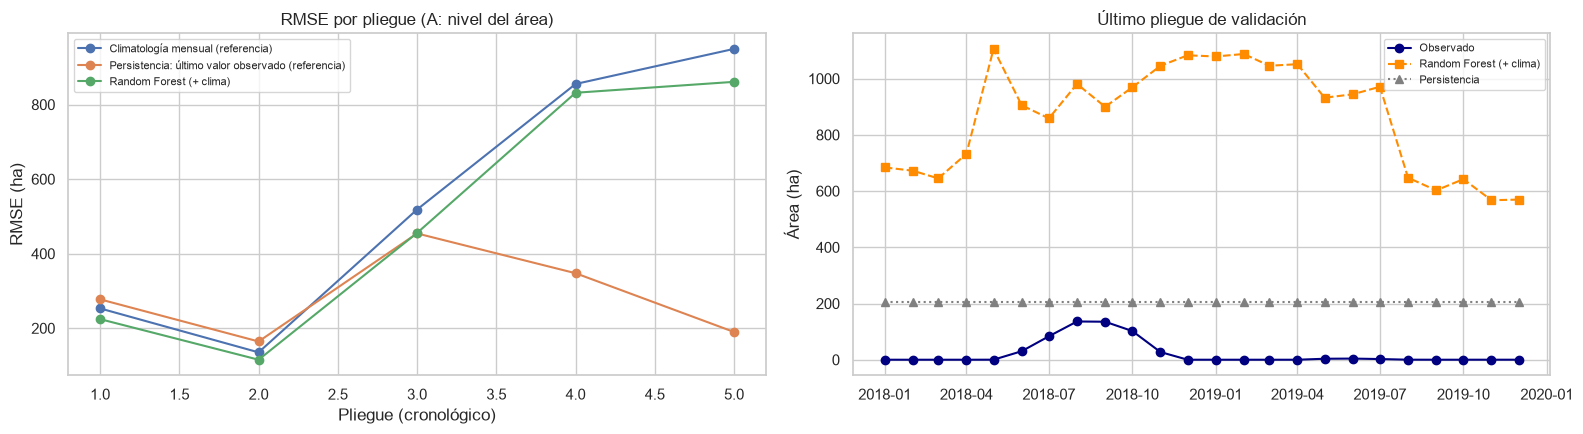

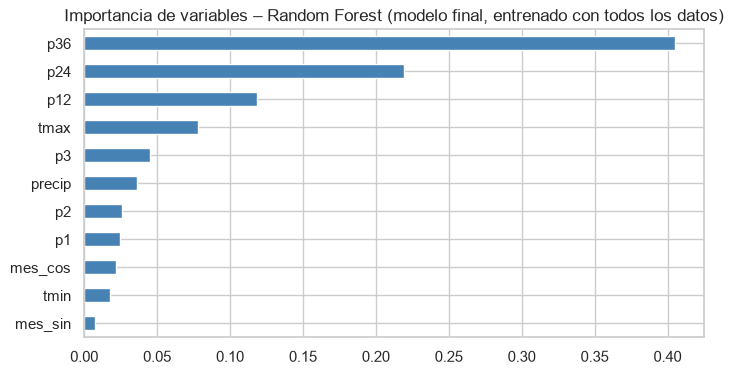

Modelo final: Random Forest | RMSE de validación cruzada: 497.58 ha


In [13]:
# ---- Error por pliegue y último pliegue
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for nombre in ("Climatología mensual (referencia)", "Persistencia: último valor observado (referencia)", MEJOR_A):
    axes[0].plot(range(1, len(pliegues_A) + 1), pliegues_A[nombre], "o-", label=nombre)
axes[0].set(title="RMSE por pliegue (A: nivel del área)", xlabel="Pliegue (cronológico)", ylabel="RMSE (ha)")
axes[0].legend(fontsize=8)

fechas_u, real_u, pred_u = ultimo_A[MEJOR_A]
_, _, pred_pers = ultimo_A["Persistencia: último valor observado (referencia)"]
axes[1].plot(fechas_u, real_u, "o-", color="navy", label="Observado")
axes[1].plot(fechas_u, pred_u, "s--", color="darkorange", label=MEJOR_A)
axes[1].plot(fechas_u, pred_pers, "^:", color="gray", label="Persistencia")
axes[1].set(title="Último pliegue de validación", ylabel="Área (ha)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

# ---- Modelo final (nivel del área, con clima) y qué variables usa
nombre_modelo = MEJOR_A.split(" (")[0]
FEATS_FINAL = FEATS_CLIMA
modelo_final = clone(MODELOS[nombre_modelo]).fit(datos[FEATS_FINAL], datos[COL_AREA])
RMSE_CV_FINAL = tabla_A.loc[MEJOR_A, "RMSE"]
estimador = modelo_final[-1] if hasattr(modelo_final, "steps") else modelo_final
if hasattr(estimador, "coef_"):
    imp, titulo = pd.Series(estimador.coef_, index=FEATS_FINAL), "Coeficientes estandarizados"
else:
    imp, titulo = pd.Series(estimador.feature_importances_, index=FEATS_FINAL), "Importancia de variables"
fig, ax = plt.subplots(figsize=(8, 4))
imp.sort_values().plot.barh(ax=ax, color="steelblue")
ax.set_title(f"{titulo} – {nombre_modelo} (modelo final, entrenado con todos los datos)")
plt.show()
print(f"Modelo final: {nombre_modelo} | RMSE de validación cruzada: {RMSE_CV_FINAL:.2f} ha")

## 8. Proyección 2025-2095 bajo RCP 2.6 y RCP 8.5

Método delta por GCM, igual que en Torca:

- Temperatura: `clima = CR2MET(1986-2005) + (GCM escenario − GCM histórico 1986-2005)`.
- Precipitación: `clima = CR2MET(1986-2005) × (GCM escenario / GCM histórico 1986-2005)`, con cociente acotado en [0, 3]. Los archivos de precipitación del CR2 son un **índice normalizado** (promedio 1986-2005 = 100), no milímetros.

Los acumulados de 12, 24 y 36 meses se arman con el clima delta desde `DESDE_LAGS` (diciembre de 2021), de modo que al empezar la proyección ya tienen su ventana completa. Eso significa que 2022-2024 aparece con clima "de escenario", no con la sequía y las lluvias reales de esos años.

Se mantiene la **corrida de control** (clima constante 1986-2005). Solo la diferencia entre escenario y control es atribuible al cambio climático según el modelo. **Si la sección 7 no muestra que el clima mejora el pronóstico, la proyección es un análisis de sensibilidad y no una predicción con respaldo estadístico.** Las predicciones se acotan a ≥ 0 ha.

In [14]:
CLIM_BASE = df_clima.loc["1986":"2005"].groupby(df_clima.loc["1986":"2005"].index.month).mean()


def clima_gcm(gcm, escenario):
    """Clima mensual (precip, tmax, tmin) de un GCM bajo el método delta, desde DESDE_LAGS."""
    cols = {}
    for var in VARS_CLIMA:
        suf, df = SUFIJO_VAR[var], proy[var]
        ref = df[f"{gcm}_{suf} historical"].loc["1986":"2005"]
        ref_m = ref.groupby(ref.index.month).mean()
        ser = df[f"{gcm}_{suf} {escenario}"].loc[DESDE_LAGS:]
        m = ser.index.month
        base = CLIM_BASE[var].reindex(m).values
        if var == "precip":
            cociente = np.clip(ser.values / np.maximum(ref_m.reindex(m).values, 1.0), 0, 3)
            cols[var] = pd.Series(base * cociente, index=ser.index)
        else:
            cols[var] = pd.Series(base + (ser.values - ref_m.reindex(m).values), index=ser.index)
    return pd.DataFrame(cols)


def predecir(clima):
    X_fut = construir_features(clima).loc[INICIO_PROY:, FEATS_FINAL]
    return pd.Series(np.clip(modelo_final.predict(X_fut), 0, None), index=X_fut.index)


proy_mensual = {}
for esc in ("rcp26", "rcp85"):
    gcms = gcms_completos(esc)
    proy_mensual[esc] = pd.DataFrame({g: predecir(clima_gcm(g, esc)) for g in gcms})
    print(f"{esc.upper()}: {len(gcms)} GCMs proyectados")

idx = proy_mensual["rcp85"].index
idx_largo = pd.date_range(DESDE_LAGS, idx.max(), freq="MS")
clima_ctrl = pd.DataFrame({v: CLIM_BASE[v].reindex(idx_largo.month).values for v in VARS_CLIMA}, index=idx_largo)
control_mensual = predecir(clima_ctrl)

proy_anual = {esc: df.resample("YS").mean() for esc, df in proy_mensual.items()}
control_anual = control_mensual.resample("YS").mean()
ensamble = {esc: df.mean(axis=1) for esc, df in proy_anual.items()}

o_min, o_max = datos[COL_AREA].min(), datos[COL_AREA].max()
for esc, df in proy_mensual.items():
    fuera = ((df < o_min) | (df > o_max)).to_numpy().mean()
    print(f"{esc.upper()}: {fuera:.1%} de las predicciones mensuales caen fuera del rango observado ({o_min:.0f}–{o_max:.0f} ha)")

RCP26: 26 GCMs proyectados
RCP85: 39 GCMs proyectados
RCP26: 0.0% de las predicciones mensuales caen fuera del rango observado (0–1834 ha)
RCP85: 0.0% de las predicciones mensuales caen fuera del rango observado (0–1834 ha)


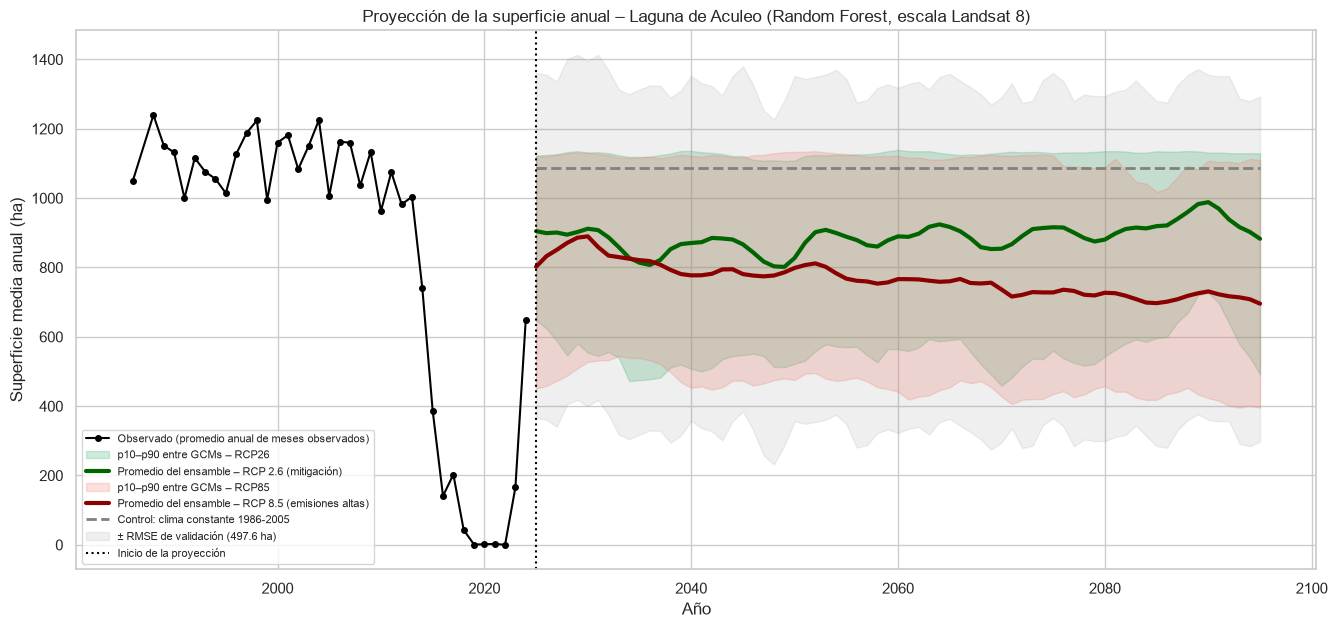

,escenario,horizonte,area_media_ha,p10_gcms,p90_gcms,efecto_vs_control_ha
0,RCP26,Corto plazo (2025-2040),874.32,652.76,1015.76,-212.88
1,RCP26,Mediano plazo (2041-2070),871.86,760.94,985.61,-215.34
2,RCP26,Largo plazo (2071-2095),917.38,758.27,1059.26,-169.83
3,RCP85,Corto plazo (2025-2040),827.12,686.51,960.39,-260.08
4,RCP85,Mediano plazo (2041-2070),773.66,638.52,976.07,-313.54
5,RCP85,Largo plazo (2071-2095),718.21,589.67,953.12,-368.99


escenario,RCP26,RCP85,RCP85 - RCP26 (ha)
horizonte,,,
Corto plazo (2025-2040),874.32,827.12,-47.20
Largo plazo (2071-2095),917.38,718.21,-199.17
Mediano plazo (2041-2070),871.86,773.66,-98.20


Para dimensionar: RMSE de validación = 497.6 ha. Un efecto del escenario menor que ese error no es distinguible del ruido del modelo.

ADVERTENCIA: en la validación cruzada el clima no mejoró de forma clara sobre las referencias simples. Estas curvas son un análisis de sensibilidad del modelo, no una predicción con respaldo estadístico.


In [15]:
COLORES = {"rcp26": ("mediumseagreen", "darkgreen", "RCP 2.6 (mitigación)"),
           "rcp85": ("salmon", "darkred", "RCP 8.5 (emisiones altas)")}

fig, ax = plt.subplots(figsize=(16, 7))
hist = anual["area_media_obs"]
ax.plot(pd.to_datetime(hist.index.astype(str)), hist.values, "o-", color="black", lw=1.5, ms=4,
        label="Observado (promedio anual de meses observados)")
for esc, (c_fino, c_grueso, etiqueta) in COLORES.items():
    q10, q90 = proy_anual[esc].quantile(0.1, axis=1), proy_anual[esc].quantile(0.9, axis=1)
    ax.fill_between(q10.index, q10.rolling(5, center=True, min_periods=1).mean(),
                    q90.rolling(5, center=True, min_periods=1).mean(), color=c_fino, alpha=0.25,
                    label=f"p10–p90 entre GCMs – {esc.upper()}")
    ax.plot(ensamble[esc].index, ensamble[esc].rolling(5, center=True, min_periods=1).mean(),
            color=c_grueso, lw=3, label=f"Promedio del ensamble – {etiqueta}")
ax.plot(control_anual.index, control_anual.values, color="gray", ls="--", lw=2, label="Control: clima constante 1986-2005")
ens_global = pd.concat(ensamble.values(), axis=1).mean(axis=1)
ax.fill_between(ens_global.index, ens_global - RMSE_CV_FINAL, ens_global + RMSE_CV_FINAL, color="gray", alpha=0.12,
                label=f"± RMSE de validación ({RMSE_CV_FINAL:.1f} ha)")
ax.axvline(pd.Timestamp(INICIO_PROY), color="black", ls=":", label="Inicio de la proyección")
ax.set(title=f"Proyección de la superficie anual – Laguna de Aculeo ({nombre_modelo}, escala Landsat 8)",
       xlabel="Año", ylabel="Superficie media anual (ha)")
ax.legend(loc="best", fontsize=8)
plt.show()

ULT = int(proy_anual["rcp85"].index.year.max())
HORIZONTES = {"Corto plazo (2025-2040)": ("2025", "2040"),
              "Mediano plazo (2041-2070)": ("2041", "2070"),
              f"Largo plazo (2071-{ULT})": ("2071", str(ULT))}
filas = []
for esc in ("rcp26", "rcp85"):
    for nombre, (a, b) in HORIZONTES.items():
        medias_gcm = proy_anual[esc].loc[a:b].mean()
        ctrl = control_anual.loc[a:b].mean()
        filas.append((esc.upper(), nombre, medias_gcm.mean(), medias_gcm.quantile(0.1), medias_gcm.quantile(0.9),
                      medias_gcm.mean() - ctrl))
resumen_proy = pd.DataFrame(filas, columns=["escenario", "horizonte", "area_media_ha", "p10_gcms", "p90_gcms",
                                            "efecto_vs_control_ha"]).round(2)
display(resumen_proy)
dif = resumen_proy.pivot(index="horizonte", columns="escenario", values="area_media_ha")
dif["RCP85 - RCP26 (ha)"] = dif["RCP85"] - dif["RCP26"]
display(dif.round(2))
print(f"Para dimensionar: RMSE de validación = {RMSE_CV_FINAL:.1f} ha. Un efecto del escenario menor que ese error no es distinguible del ruido del modelo.")
AYUDA_CLIMA = CLIMA_AYUDA_A or CLIMA_AYUDA_B
if not AYUDA_CLIMA:
    print("\nADVERTENCIA: en la validación cruzada el clima no mejoró de forma clara sobre las referencias simples. "
          "Estas curvas son un análisis de sensibilidad del modelo, no una predicción con respaldo estadístico.")

## 9. Exportación, resumen y comparación con Torca

In [16]:
df_modelo.to_csv(DIR_PROC / f"base_mensual{SUF}_v1.csv")
serie_curada.to_csv(DIR_PROC / f"serie_curada_calibrada{SUF}_v1.csv")
tabla_cal.to_csv(DIR_PROC / f"calibracion_sensores{SUF}_v1.csv")
anual.to_csv(DIR_PROC / f"variacion_anual{SUF}_v1.csv")
tabla_corr.to_csv(DIR_PROC / f"correlaciones{SUF}_v1.csv")
tabla_A.to_csv(DIR_PROC / f"cv_nivel_area{SUF}_v1.csv")
tabla_B.to_csv(DIR_PROC / f"cv_anomalias{SUF}_v1.csv")
resumen_proy.to_csv(DIR_PROC / f"resumen_proyecciones{SUF}_v1.csv", index=False)
for esc, df in proy_anual.items():
    df.to_csv(DIR_PROC / f"proyeccion_anual_{esc}{SUF}_v1.csv")
control_anual.rename("control").to_csv(DIR_PROC / f"proyeccion_anual_control{SUF}_v1.csv")
print("Archivos guardados en:", DIR_PROC.resolve())

print("\n===== RESUMEN AUTOMÁTICO DE ESTA EJECUCIÓN (ACULEO) =====")
print(f"• Observaciones válidas: {int(serie_curada[COL_AREA].notna().sum())} escenas | {n_obs} meses con área | {len(datos)} con área y clima")
print(f"• Calibración entre sensores: {'aplicada' if PUENTE_OK else 'NO disponible (se usó `epoca`)'}"
      + (f" | factores a escala L8: { {k.replace('LANDSAT_', 'L'): round(v, 3) for k, v in FACTORES.items()} }" if PUENTE_OK else ""))
print(f"• Mayor |rho| área–clima (anomalías estacionales): {mejor} = {RHO_MAX:+.2f} (R² ≈ {RHO_MAX ** 2:.0%}; "
      f"n efectivo ≈ {tabla_corr.loc[mejor, 'n_efectivo']:.0f})")
print(f"• Nivel del área: mejor con clima = {MEJOR_A} → {'supera' if CLIMA_AYUDA_A else 'no supera claramente'} a las referencias simples")
print(f"• Anomalías: mejor con clima = {MEJOR_B} → {'supera' if CLIMA_AYUDA_B else 'no supera claramente'} a las referencias simples")

Archivos guardados en: C:\Users\jp200\Escritorio\Predicción laguna torca\data\processed

===== RESUMEN AUTOMÁTICO DE ESTA EJECUCIÓN (ACULEO) =====
• Observaciones válidas: 687 escenas | 343 meses con área | 286 con área y clima
• Calibración entre sensores: aplicada | factores a escala L8: {'L8': 1.0, 'L9': 1.0, 'L7': 1.04, 'L5': 1.027}
• Mayor |rho| área–clima (anomalías estacionales): p36 = +0.47 (R² ≈ 22%; n efectivo ≈ 12)
• Nivel del área: mejor con clima = Random Forest (+ clima) → no supera claramente a las referencias simples
• Anomalías: mejor con clima = Random Forest (+ clima) → no supera claramente a las referencias simples


In [17]:
# ---- Comparación con Torca (si sus resultados están en data/processed)
ruta_corr_t = buscar_archivo("correlaciones_v2.csv", (DIR_PROC,))
ruta_cv_t = buscar_archivo("cv_nivel_area_v2.csv", (DIR_PROC,))
ruta_cvB_t = buscar_archivo("cv_anomalias_v2.csv", (DIR_PROC,))
if ruta_corr_t is None or ruta_cv_t is None:
    print("No encuentro los resultados de Torca (correlaciones_v2.csv, cv_nivel_area_v2.csv) en data/processed: se omite la comparación.")
else:
    ct = pd.read_csv(ruta_corr_t, index_col=0)
    cmp_rho = pd.DataFrame({"Torca": ct["rho_anom_estacional"].abs().max(), "Aculeo": tabla_corr["rho_anom_estacional"].abs().max()},
                           index=["máx |rho| anomalía estacional"])
    cmp_rho.loc["máx |rho| exigente"] = [ct["rho_anom_sin_epoca"].abs().max() if "rho_anom_sin_epoca" in ct else np.nan,
                                         tabla_corr["rho_anom_estacional"].abs().max()]

    def aporte_clima(tabla):
        modelos = [m for m in MODELOS if f"{m} (+ clima)" in tabla.index]
        return np.mean([tabla.loc[f"{m} (estacionalidad)", "RMSE"] - tabla.loc[f"{m} (+ clima)", "RMSE"] for m in modelos])

    def mejor_ref(tabla):
        return tabla.loc[[i for i in tabla.index if "(referencia)" in i], "RMSE"].min()

    cvt = pd.read_csv(ruta_cv_t, index_col=0)
    cmp_cv = pd.DataFrame({"Torca": [aporte_clima(cvt), mejor_ref(cvt)], "Aculeo": [aporte_clima(tabla_A), mejor_ref(tabla_A)]},
                          index=["aporte medio del clima, RMSE ha (+ = mejora)", "RMSE de la mejor referencia (ha)"])
    display(pd.concat([cmp_rho, cmp_cv]).round(2))
    print("Lectura: si Aculeo muestra una correlación claramente mayor Y un aporte del clima positivo mayor que su ruido entre pliegues, "
          "es un mejor candidato que Torca para estudiar la respuesta al clima. Si no, el problema no era solo la laguna elegida.")

,Torca,Aculeo
máx |rho| anomalía estacional,0.18,0.47
máx |rho| exigente,0.18,0.47
"aporte medio del clima, RMSE ha (+ = mejora)",-0.05,34.30
RMSE de la mejor referencia (ha),7.82,286.67


Lectura: si Aculeo muestra una correlación claramente mayor Y un aporte del clima positivo mayor que su ruido entre pliegues, es un mejor candidato que Torca para estudiar la respuesta al clima. Si no, el problema no era solo la laguna elegida.


## Notas metodológicas

- **Sin imputación, sin suavizado.** Igual que en Torca: las secciones de MICE y del modelo anual del notebook original no se replican aquí. Si se quieren, se agregan como en el notebook de Torca.
- **Qué se cambió respecto de Torca y por qué.** (1) No se anulan áreas bajas ni caídas por sí mismas: en una laguna que se seca son reales. (2) Se filtra por `frac_valida`, que mide directamente cuánto polígono se ve. (3) El cambio de sensor se estima con pares de escenas casi simultáneas; restar la media de cada época sería incorrecto aquí porque confunde sensor con sequía. (4) Se agregan acumulados de lluvia de 24 y 36 meses.
- **Calibración multiplicativa.** Se asume que el sesgo entre misiones es proporcional al área (efecto de borde con el umbral NDWI). Los gráficos de pares permiten comprobarlo: si la nube de puntos no pasa por el origen, el sesgo es más bien aditivo.
- **Piso de detección.** Con la laguna seca el área no llega a cero (suelo húmedo, canales, cultivos regados con NDWI > 0). No se resta; se informa en la sección 2.
- **Clima hasta 2019.** CR2MET termina antes de la sequía profunda y de la recuperación de 2023-2024. Es la principal limitación para evaluar la respuesta de la laguna al clima.
- **Proyecciones.** Los archivos CR2 son los de Torca salvo que existan en `data/raw/aculeo/`. El método delta usa cambios relativos, pero la ubicación importa.
- **Usos del agua.** Aculeo está rodeada de zonas agrícolas y de parcelación, y su recuperación depende también de napas y extracciones. El clima es solo una de las posibles explicaciones; un modelo climático que no mejora a la persistencia es un resultado válido y esperable en ese contexto.
- **Validación.** Ventana expansiva, siempre fuera de la muestra, y comparación explícita con la climatología y la persistencia. Los predictores son concurrentes (clima real del mismo mes), más favorable que pronosticar a ciegas.
- **n efectivo.** Los acumulados de 12-36 meses y el área cambian lento; los p-valores con 200 meses sobreestiman la evidencia. Usar `n_efectivo` y la estabilidad antes/después de 2012.
- **No incluido.** Sentinel-2, nivel o caudal medido (DGA), extracciones, uso del suelo.

In [20]:
import cdsapi

dataset = "reanalysis-era5-land-monthly-means"
request = {
    "product_type": ["monthly_averaged_reanalysis"],
    "variable": [
        "volumetric_soil_water_layer_1",
        "total_evaporation",
        "total_precipitation"
    ],
    "year": [
        "1985", "1986", "1987",
        "1988", "1989", "1990",
        "1991", "1992", "1993",
        "1994", "1995", "1996",
        "1997", "1998", "1999",
        "2000", "2001", "2002",
        "2003", "2004", "2005",
        "2006", "2007", "2008",
        "2009", "2010", "2011",
        "2012", "2013", "2014",
        "2015", "2016", "2017",
        "2018", "2019", "2020",
        "2021", "2022", "2023",
        "2024", "2025", "2026"
    ],
    "month": [
        "01", "02", "03",
        "04", "05", "06",
        "07", "08", "09",
        "10", "11", "12"
    ],
    "time": ["00:00"],
    "data_format": "netcdf",
    "download_format": "unarchived"
}

client = cdsapi.Client()
client.retrieve(dataset, request).download()


Exception: Missing/incomplete configuration file: C:\Users\jp200/.cdsapirc